[← Sumário da disciplina](README.md)

# Processamento SAR I

**Maj Diego - 1° Semestre / 2027**

**Objetivos**

1. Distinguir resolução espacial e amostragem
2. Explicar compressão de pulso e focalização SAR
3. Relacionar algoritmos de formação e qualidade da imagem

**Referências da aula**

- ISO/TS 19130-2:2014, *Geographic information — Imagery sensor models for geopositioning — Part 2: SAR, InSAR, lidar and sonar*. Leitura dirigida: seções 7.1–7.2; Anexo C.
- THE SAR HANDBOOK, *Comprehensive Methodologies for Forest Monitoring and Biomass Estimation*. First edition. Published electronically. April 2019. Disponível em https://www.earthdata.nasa.gov/learn/earth-observation-data-basics/sar-handbook.

## O problema

Dois objetos aparecem separados em um produto e fundidos em outro, mesmo com pixels do mesmo tamanho. Como a largura de banda, a antena e o processamento determinam o detalhe realmente observável?

$$
\boxed{\text{Ecos complexos}} \rightarrow \boxed{\text{Compressão em alcance}} \rightarrow \boxed{\text{Focalização em azimute}}
$$

## 1. SAR

### 1.1. Abertura sintética
O Synthetic Aperture Radar combina coerentemente os ecos de um alvo observados em diferentes posições da trajetória $(L)$. A variação de fase permite simular uma abertura maior que a antena física $(d_a)$. 

<img src="media/imgs/img11.png"  alt="sar">

Sob hipóteses idais, a resolução azimutal é aproximadamente:

$$
\boxed{\delta_{az,SAR}\approx\frac{d_a}{2}}
$$

> Observe que a resolução em azimute **não depende da distância ao alvo**. Isso permite obter imagens de alta resolução a partir de aeronaves e satélites, sem exigir antenas fisicamente gigantescas.

### 1.2. Informação para geoposicionar

O produto precisa informar tempo, trajetória, parâmetros de alcance e modo de aquisição.

### 1.3. Distorções radiométricas

As imagens SAR também são caracterizadas por uma aparência um tanto granulada, que se assemelha ao ruído do tipo "sal e pimenta". Normalmente denominado *speckle*, este efeito é inerente a todos os sistemas de imageamento coerente de banda estreita e resulta da interferência entre os inúmeros ecos de espalhamento presentes dentro de uma célula de resolução.

#### 1.3.1. A origem intrínseca do ruído *speckle*

Em uma imagem SAR de média resolução, a resposta de espalhamento de uma célula de resolução (10 × 10 m no Sentinel-1) é a soma coerente de <b style="color:#2ECC40">milhares de eventos individuais de espalhamento</b>. 

Devido às diferentes posições desses espalhadores dentro da célula de resolução,<b style="color:#2ECC40"> a fase e a amplitude de cada espalhador individual varia aleatoriamente</b>, de modo que a resposta de espalhamento de um pixel corresponde à soma de milhares de vetores aleatórios (seta preta na fig abaixo).

<img src="media/imgs/img15.jpg"  alt="speckle">

#### 1.3.2. Filtragens do ruído *speckle* 

Ruídos como o speckle são difíceis de tratar, pois os parâmetros que os governam são desconhecidos. Por essa razão, ao longo da última década, muitos esforços foram dedicados ao desenvolvimento de filtros eficazes para redução do speckle, resultando em uma grande variedade de métodos de filtragem.

Entre os filtros mais relevantes e amplamente conhecidos tem-se:

| Speckle Filter | Descrição | Publicação(ões) Relacionada(s) |
|----------------|-----------|--------------------------------|
| **Change-preserving multi-temporal Speckle filter** | Filtro para pilhas de imagens SAR; reduz o speckle enquanto preserva mudanças na série temporal (por exemplo, relacionadas ao desmatamento). | Quegan and Yu, 2001 |
| **Lee filter** | Filtro baseado no desvio-padrão (sigma), que realiza a filtragem utilizando estatísticas calculadas a partir dos dados. Diferentemente dos filtros Gaussiano ou Boxcar, o filtro Lee e outros filtros sigma semelhantes preservam a nitidez e os detalhes da imagem enquanto suprimem o ruído. | Lee, 1980 |
| **Enhanced Lee filter** | O filtro Lee aprimorado é uma adaptação do filtro Lee. Cada pixel é classificado em uma de três categorias: <br><br>• **Homogeneous (Homogêneo):** o valor do pixel é substituído pela média da janela de filtragem. <br>• **Heterogeneous (Heterogêneo):** o valor do pixel é substituído por uma média ponderada. <br>• **Point target (Alvo pontual):** o valor do pixel não é alterado. | Lopes et al., 1990 |
| **Frost and enhanced Frost filters** | O filtro Frost é um filtro exponencialmente amortecido e circularmente simétrico que utiliza estatísticas locais. O filtro Frost aprimorado é uma adaptação do filtro Frost. Os pixels são classificados e filtrados de acordo com a lógica descrita acima. | Frost et al., 1982; Lopes et al., 1990 |
| **Non-local means filters** | A ideia básica dos filtros *Non-Local Means* é fornecer uma estimativa da imagem limpa por meio da média apropriada de pixels ou regiões semelhantes encontrados na imagem. Essencialmente, o algoritmo procura regiões da imagem que se assemelhem à área ao redor do pixel a ser filtrado. Com base em um critério de similaridade, essas regiões são encontradas e combinadas para reduzir o ruído sem perda de resolução. | Buades et al., 2005; Chen et al., 2014; Di Martino et al., 2016; Martino et al., 2015 |

### 1.4. Distorções geométricas

O SAR é um sensor de **visada lateral**. Na direção de alcance, os alvos são posicionados pelo tempo de ida e volta do pulso; em azimute, pelo processamento dos ecos ao longo da trajetória. Essa geometria produz uma representação diferente da vista em planta de um mapa, mesmo em terreno plano.

<img src="media/imgs/img20.png"  alt="slant range">


#### 1.4.3. Correção geométrica

A conversão de *slant range* para *ground range* reamostra os dados para uma superfície de referência. Essa etapa corrige a variação de escala associada à projeção, mas, quando utiliza apenas um elipsoide ou uma altura média, ainda pode deixar deslocamentos causados pelo relevo.

<img src="media/imgs/img21.png"  alt="ground range">



### 1.5. Distorções do relevo

Observe abaixo como o relevo pode introduzir distorções no mapeamento. A correção geométrica usa trajetória e deve ser completada por algum modelo de elevação. 

<img src="media/imgs/img22.png"  alt="dsitorções devido ao relevo">

### 2. Como SAR imageia o mundo?

Os sistemas <b style="color:#2ECC40"> SAR não medem diretamente a potência recebida</b> $(P_R)$, vista anteriormente na Equação RADAR. Eles recebem um campo eletromagnético que é convertido em um sinal elétrico. Após a demodulação coerente, esse sinal é armazenado por duas componentes:

- $I$ (In-phase): componente em fase com a referência do receptor.
- $Q$ (Quadrature): componente em quadratura, defasada de 90° em relação à referência.

Juntas, elas formam o sinal complexo:

$
\boxed{S=I+jQ=Ae^{j\phi}}
$

A partir dele, podemos calcular:
$
\underbrace{A=\sqrt{I^2+Q^2}}_{\text{Amplitude}}
\ ,  \qquad 
\underbrace{\phi=\operatorname{atan2}(Q,I)=\arg(S)}_{\text{Fase}}
\qquad  e  \qquad 
\underbrace{|S|^2=I^2+Q^2}_{\text{Intensidade } \propto P_R}
$


> Após o processamento bruto dos dados, a intensidade recebida compõe os valores digitais dos pixels de uma imagem complexa que recebe o nome de imagem SLC (*Single Look Complex)*

### 2.1 Imagens SLC

#### 2.1.1 Busca, download e visualização de imagem SLC do Sentinel-1

In [5]:
# Busca pública no catálogo STAC da Copernicus (não requer credenciais).
from datetime import datetime, timedelta, timezone
from pystac_client import Client

catalogo = Client.open("https://stac.dataspace.copernicus.eu/v1/", timeout=60)
agora = datetime.now(timezone.utc)
inicio = agora - timedelta(days=30)
# Centro de Manaus, em longitude/latitude (WGS84).
manaus = {"type": "Point", "coordinates": [-60.0217, -3.1190]}

busca = catalogo.search(
    collections=["sentinel-1-slc"],
    intersects=manaus,
    datetime=f"{inicio:%Y-%m-%dT%H:%M:%SZ}/{agora:%Y-%m-%dT%H:%M:%SZ}",
    sortby="-datetime",
    max_items=100,
)
# IW é o modo de aquisição utilizado neste exemplo.
cenas_slc = [item for item in busca.items()
             if item.properties.get("sar:instrument_mode") == "IW"]
print(f"Cenas encontradas: {len(cenas_slc)}")
if not cenas_slc:
    raise RuntimeError("Nenhuma cena SLC IW sobre Manaus nos ?ltimos 30 dias.")
cena_slc = max(cenas_slc, key=lambda item: item.datetime)
print(f"Cena selecionada: {cena_slc.id}")
print(f"Aquisição (UTC): {cena_slc.datetime:%Y-%m-%d %H:%M:%S}")
print("Polarizações:", cena_slc.properties.get("sar:polarizations"))
print("URL do produto:", cena_slc.assets["product"].href)
cena_slc

Cenas encontradas: 2
Cena selecionada: S1D_IW_SLC__1SDV_20261115T093845_20261115T093911_005476_00A76C_E950
Aquisição (UTC): 2026-11-15 09:38:45
Polarizações: ['VV', 'VH']
URL do produto: https://download.dataspace.copernicus.eu/odata/v1/Products(1eb05fdb-1f7d-403b-a059-b7e480975cec)/$value


<Item id=S1D_IW_SLC__1SDV_20261115T093845_20261115T093911_005476_00A76C_E950>

In [9]:
## Run write one time with Copernicus Data Space Ecosystem (CDSE) credentials
# with open('copernicus_cred.txt', 'w', encoding='utf-8') as file:
#   file.write("email:senha")

## Open file in read-only mode
with open('copernicus_cred.txt', 'r', encoding='utf-8') as file:
  txt = file.read()
  usuario, senha = txt.split(":")

In [10]:
# Download do produto SLC completo (.SAFE.zip), preservando amplitude e fase.
from pathlib import Path
import zipfile
import requests
from tqdm.auto import tqdm

if "cena_slc" not in globals():
    raise RuntimeError("Execute primeiro a célula de busca.")

# O STAC identifica a cena; o OData fornece o UUID e o download autenticado.
nome_produto = cena_slc.id.removesuffix(".SAFE") + ".SAFE"
resposta = requests.get(
    "https://catalogue.dataspace.copernicus.eu/odata/v1/Products",
    params={"$filter": "Name eq '" + nome_produto.replace("'", "''") + "'"},
    timeout=60,
)
resposta.raise_for_status()
produtos = resposta.json()["value"]
if len(produtos) != 1:
    raise RuntimeError("Não foi possível identificar unicamente o produto no OData.")
produto = produtos[0]
if not produto.get("Online", True):
    raise RuntimeError("A cena está offline; selecione outra cena recente.")

pasta = Path("downloads/sentinel1_slc")
pasta.mkdir(parents=True, exist_ok=True)
arquivo_slc = pasta / (nome_produto + ".zip")
parcial = arquivo_slc.with_suffix(".zip.part")
print(f"Produto: {nome_produto}")
print(f"Tamanho informado: {produto.get('ContentLength', 0) / 1024**3:.2f} GiB")

if arquivo_slc.exists() and zipfile.is_zipfile(arquivo_slc):
    print(f"Produto á? disponível: {arquivo_slc.resolve()}")
else:
    try:
        autenticacao = requests.post(
            "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token",
            data={"client_id": "cdse-public", "grant_type": "password",
                  "username": usuario.strip(), "password": senha},
            timeout=60,
        )
    finally:
        del usuario, senha
    if not autenticacao.ok:
        raise RuntimeError(f"Falha na autentica??o Copernicus (HTTP {autenticacao.status_code}).")
    token = autenticacao.json()["access_token"]
    del autenticacao
    url = f"https://download.dataspace.copernicus.eu/odata/v1/Products({produto['Id']})/$value"
    try:
        with requests.get(url, headers={"Authorization": f"Bearer {token}"},
                          stream=True, timeout=(30, 180)) as resposta_download:
            if not resposta_download.ok:
                raise RuntimeError(f"Falha no download (HTTP {resposta_download.status_code}).")
            total = int(resposta_download.headers.get("Content-Length", 0))
            with parcial.open("wb") as destino, tqdm(
                total=total or None, unit="B", unit_scale=True, desc="Downloading..."
            ) as progresso:
                for bloco in resposta_download.iter_content(chunk_size=8 * 1024 * 1024):
                    if bloco:
                        destino.write(bloco)
                        progresso.update(len(bloco))
            if total and parcial.stat().st_size != total:
                raise IOError("Download incompleto; execute novamente esta célula.")
        if not zipfile.is_zipfile(parcial):
            raise IOError("O arquivo recebido não é um ZIP válido.")
        parcial.replace(arquivo_slc)
    finally:
        del token
        # Evita manter o cabeçalho de autorização no namespace do notebook.
        if "resposta_download" in globals():
            del resposta_download
    print(f"Download concluído: {arquivo_slc.resolve()}")

Produto: S1D_IW_SLC__1SDV_20261115T093845_20261115T093911_005476_00A76C_E950.SAFE
Tamanho informado: 7.29 GiB


Downloading...:   0%|          | 0.00/7.83G [00:00<?, ?B/s]

Download concluído: D:\SE6\SensoresAtivos\downloads\sentinel1_slc\S1D_IW_SLC__1SDV_20261115T093845_20261115T093911_005476_00A76C_E950.SAFE.zip


IW1/VV: 21854 × 13437 pixels; prévia 1057 × 650; complex_int16
IW2/VV: 25659 × 13536 pixels; prévia 1232 × 650; complex_int16
IW3/VV: 24672 × 13572 pixels; prévia 1182 × 650; complex_int16
Amplitude conjunta: P2=12.30, mediana=38.95, P98=48.53 dB re 1 DN


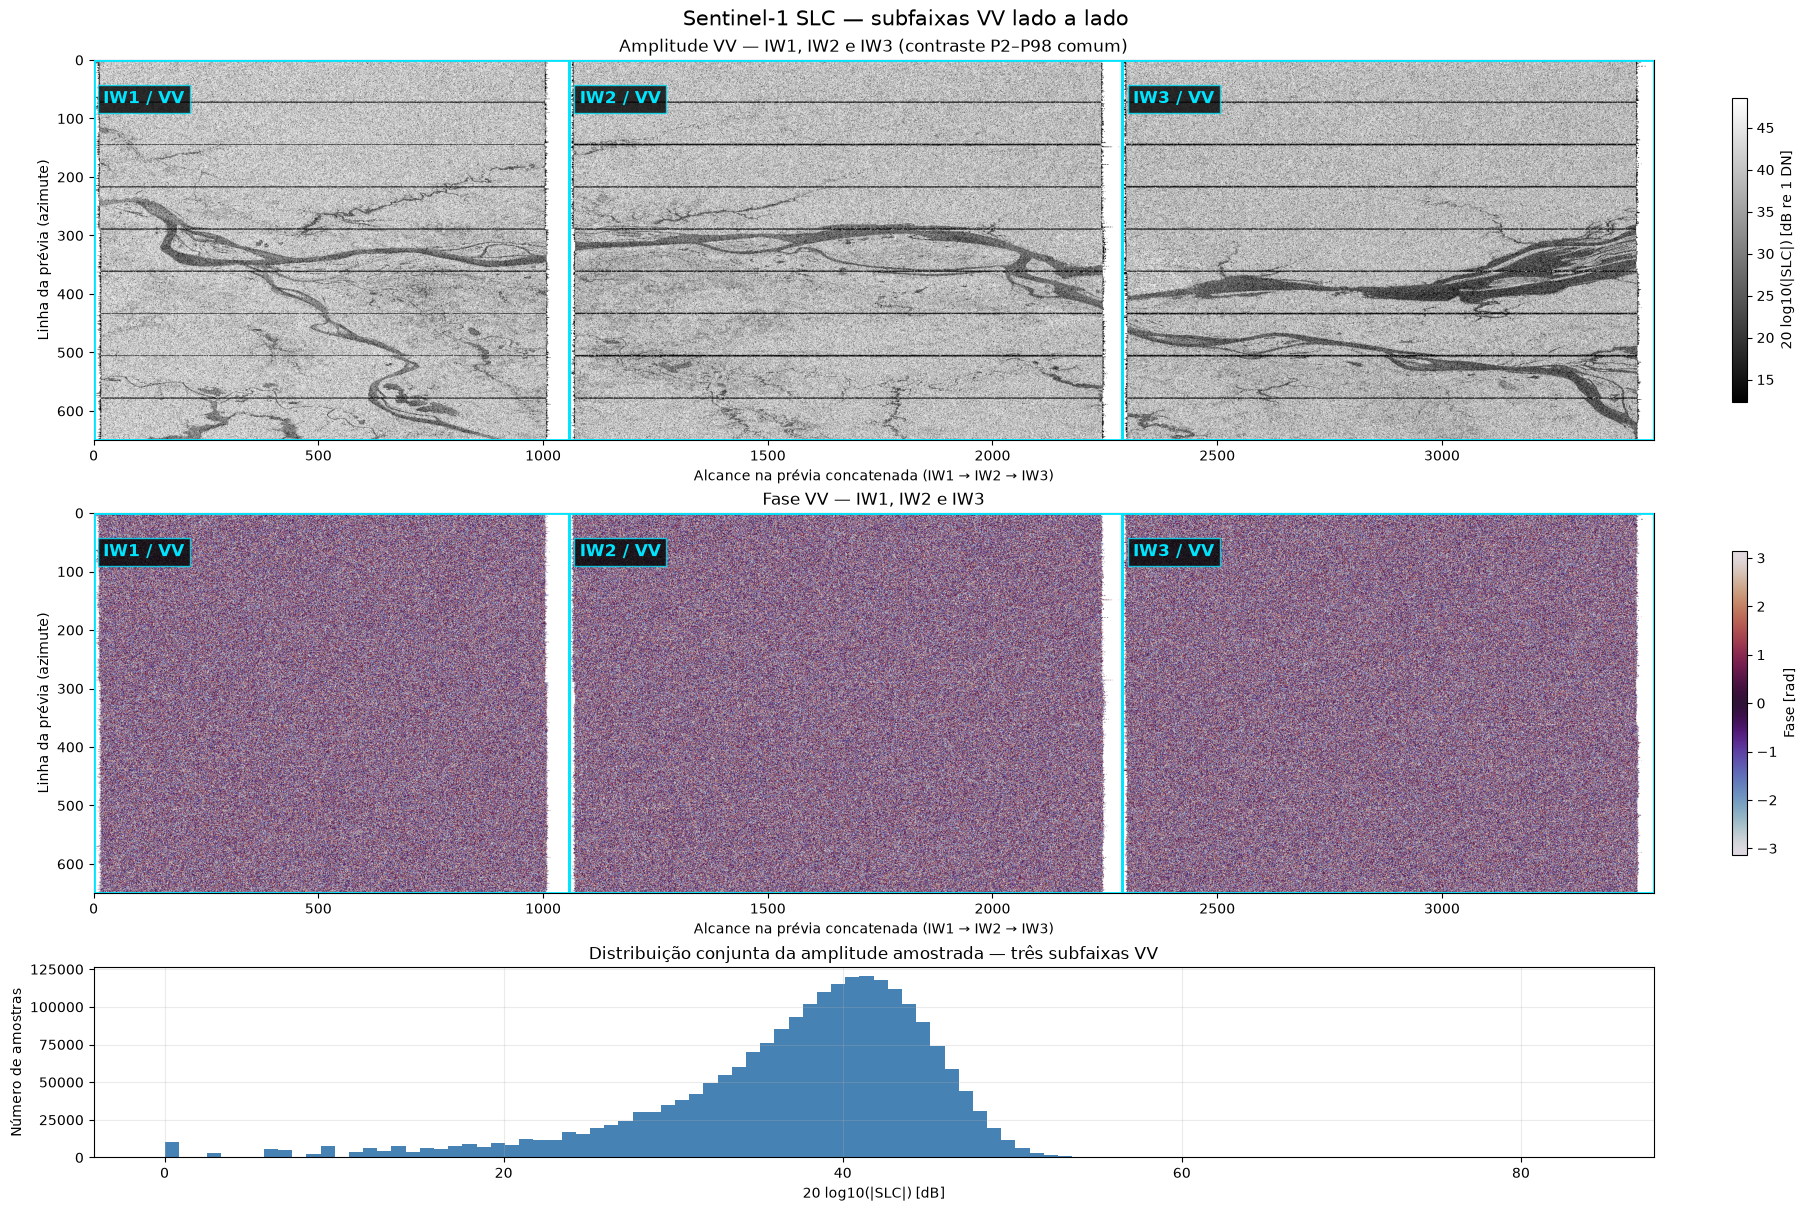

In [35]:
# Visualização e análise do produto SLC baixado, sem extrair todo o ZIP.
from pathlib import Path
from zipfile import ZipFile, is_zipfile
import xml.etree.ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling

# Pode também ser executada em uma sessão nova, após o download.
if "arquivo_slc" not in globals():
    arquivos = sorted(Path("downloads/sentinel1_slc").glob("*.zip"),
                      key=lambda p: p.stat().st_mtime, reverse=True)
    if not arquivos:
        raise FileNotFoundError("Execute primeiro a célula de download.")
    arquivo_slc = arquivos[0]
arquivo_slc = Path(arquivo_slc)
if not arquivo_slc.is_file() or not is_zipfile(arquivo_slc):
    raise ValueError("O produto informado não é um arquivo ZIP válido.")

# Dispõe IW1, IW2 e IW3 horizontalmente em alcance; não cria um mosaico geográfico.
from matplotlib.patches import Rectangle

subfaixas = ("iw1", "iw2", "iw3")
polarizacao = "vv"
previas = []
with ZipFile(arquivo_slc) as zip_slc:
    medidas = sorted(m for m in zip_slc.namelist()
                     if "/measurement/" in m and m.lower().endswith((".tif", ".tiff")))
    for subfaixa in subfaixas:
        candidatas = [m for m in medidas if f"-{subfaixa}-slc-{polarizacao}-" in m.lower()]
        if len(candidatas) != 1:
            raise ValueError(f"Esperada uma imagem {subfaixa.upper()}/VV no ZIP.")
        medida = candidatas[0]
        # Mesma altura de prévia para alinhar as subfaixas horizontalmente.
        with rasterio.open(f"/vsizip/{arquivo_slc.resolve().as_posix()}/{medida}") as src:
            altura_previa = min(650, src.height)
            largura_previa = max(1, round(src.width * altura_previa / src.height))
            slc = src.read(1, out_shape=(altura_previa, largura_previa),
                           out_dtype="complex64", resampling=Resampling.nearest)
            print(f"{subfaixa.upper()}/VV: {src.width} × {src.height} pixels; "
                  f"prévia {largura_previa} × {altura_previa}; {src.dtypes[0]}")
        amplitude = np.abs(slc)
        validos = np.isfinite(slc) & (amplitude > 0)
        if not validos.any():
            raise ValueError(f"Sem amostras válidas em {subfaixa.upper()}.")
        amplitude_db = np.full(slc.shape, np.nan, dtype="float32")
        amplitude_db[validos] = 20 * np.log10(amplitude[validos])
        fase = np.where(validos, np.angle(slc), np.nan)
        previas.append((subfaixa.upper(), amplitude_db, fase))

# Uma escala de amplitude comum permite comparar as três subfaixas.
amostras_db = np.concatenate([a[np.isfinite(a)] for _, a, _ in previas])
p2, mediana_db, p98 = np.percentile(amostras_db, [2, 50, 98])
print(f"Amplitude conjunta: P2={p2:.2f}, mediana={mediana_db:.2f}, P98={p98:.2f} dB re 1 DN")

fig, eixos = plt.subplots(3, 1, figsize=(18, 12),
                          gridspec_kw={"height_ratios": [2, 2, 1]}, constrained_layout=True)
altura_total = max(a.shape[0] for _, a, _ in previas)
largura_total = sum(a.shape[1] for _, a, _ in previas)
for indice, (titulo, cmap, minimo, maximo, unidade) in enumerate([
    ("Amplitude VV — IW1, IW2 e IW3 (contraste P2–P98 comum)", "gray", p2,
     p98 if p98 > p2 else p2 + 1, "20 log10(|SLC|) [dB re 1 DN]"),
    ("Fase VV — IW1, IW2 e IW3", "twilight", -np.pi, np.pi, "Fase [rad]"),
]):
    eixo = eixos[indice]
    esquerda = 0
    for rotulo, amplitude_db, fase in previas:
        dados = amplitude_db if indice == 0 else fase
        altura, largura = dados.shape
        im = eixo.imshow(dados, cmap=cmap, vmin=minimo, vmax=maximo,
                         extent=(esquerda, esquerda + largura, altura, 0), aspect="auto")
        # Contorno e anotação delimitam exatamente a prévia de cada IW.
        eixo.add_patch(Rectangle((esquerda, 0), largura, altura, fill=False,
                                 edgecolor="#00E5FF", linewidth=2, zorder=3))
        eixo.annotate(rotulo + " / VV", xy=(esquerda + 0.02 * largura, 0.08 * altura),
                      color="#00E5FF", fontsize=12, fontweight="bold", va="top",
                      bbox=dict(facecolor="black", alpha=0.8, edgecolor="#00E5FF", pad=4),
                      zorder=4)
        esquerda += largura
    eixo.set(xlim=(0, largura_total), ylim=(altura_total, 0), title=titulo,
             xlabel="Alcance na prévia concatenada (IW1 → IW2 → IW3)",
             ylabel="Linha da prévia (azimute)")
    fig.colorbar(im, ax=eixo, label=unidade, shrink=0.8)

eixos[2].hist(amostras_db, bins=100, color="steelblue")
eixos[2].set(title="Distribuição conjunta da amplitude amostrada — três subfaixas VV",
             xlabel="20 log10(|SLC|) [dB]", ylabel="Número de amostras")
eixos[2].grid(alpha=0.25)
fig.suptitle("Sentinel-1 SLC — subfaixas VV lado a lado", fontsize=15)
plt.show()

#### 2.1.2. Software SNAP

Os dados GeoTIFFs "tipo complexo" [não podem ser exibidos pelo QGIS](https://github.com/qgis/QGIS/issues/25226). 

In [41]:
qgis_bin_path = 'C:/Program Files/QGIS 3.44.11/bin' # 'ajustar
file = f"/vsizip/{arquivo_slc.resolve().as_posix()}/{medida}"

# if in CMD shell, print last 14 lines of gdalinfo output
!"{qgis_bin_path}/gdalinfo.exe" "{file}" | python -c "import sys; [print(l.rstrip()) for l in list(sys.stdin)[-14:]]"

Metadata:
  TIFFTAG_IMAGEDESCRIPTION=Sentinel-1A IW SLC L1
  TIFFTAG_SOFTWARE=Sentinel-1 IPF 004.03
  TIFFTAG_DATETIME=2026:11:15 14:47:08
  AREA_OR_POINT=Area
Image Structure Metadata:
  INTERLEAVE=BAND
Corner Coordinates:
Upper Left  (    0.0,    0.0)
Lower Left  (    0.0,13572.0)
Upper Right (24672.0,    0.0)
Lower Right (24672.0,13572.0)
Center      (12336.0, 6786.0)
Band 1 Block=24672x1 Type=CInt16, ColorInterp=Gray


Para isso utiliza-se o SentiNel Application Platform (SNAP) da agência espacial européia (ESA). Download: https://step.esa.int/main/download/snap-download/

<img src="media/imgs/img18.png"  alt="SNAP">

#### 2.1.3 Busca, download e visualização de imagem SCS do BIOMASS

```
Single-look Complex Slant-range (SCS): Level-1a products based on slant-range versus azimuth plane images. Each pixel of the image is represented by a complex value containing calibrated radar amplitude and phase.
```

In [ ]:
# Busca pública no catálogo STAC da ESA (não requer credenciais).
from datetime import datetime, timedelta, timezone
from pystac_client import Client

catalogo = Client.open("https://catalog.maap.eo.esa.int/catalogue/", timeout=60)
# Caixa delimitadora ao redor de Manaus (oeste, sul, leste, norte), WGS84
BBOX_MANAUS = [-60.3, -3.3, -59.8, -2.9]

busca = catalogo.search(
    method="GET",
    collections="BiomassLevel1a",
    bbox=BBOX_MANAUS,
    datetime="2025-04-01/..",
    filter=(
        "productType='S1_SCS__1S' "
        "or productType='S2_SCS__1S' "
        "or productType='S3_SCS__1S'"
    ),
    sortby="-datetime",
)

if not busca:
    raise RuntimeError("Nenhuma cena SLC IW sobre Manaus nos últimos 30 dias.")

items = list(busca.get_items())
print(f"Cenas encontradas: {len(items)}")
# items.sort(key=lambda item: item.datetime or item.properties.get("start_datetime", ""), reverse=True)

cena_slc = max(items, key=lambda item: item.datetime)
print(f"Cena selecionada: {cena_slc.id}")
print(f"Aquisição (UTC): {cena_slc.datetime:%Y-%m-%d %H:%M:%S}")
print("Polarizações:", cena_slc.properties.get("sar:polarizations"))
print("URL do produto:", cena_slc.assets["product"].href)
cena_slc

Cenas encontradas: 82
Cena selecionada: BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S
Aquisição (UTC): 2026-01-29 22:12:14
Polarizações: ['HH', 'HV', 'VH', 'VV']
URL do produto: https://catalog.maap.eo.esa.int/data/zipper/biomass-pdgs-01/BiomassLevel1a/2026/01/29/BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S/BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S


<Item id=BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S>

In [76]:
## Run write one time with ESA MAAP credentials (see https://catalog.maap.eo.esa.int/doc/examples/ESAMAAP_biomassdataaccess.html)
# obtained at https://portal.maap.eo.esa.int/ini/services/auth/token/index.php 
# with open('esa_cred.txt', 'w', encoding='utf-8') as file:
#   file.write("email:OFFLINE_TOKEN")

# Permanently valid, no need to refresh
CLIENT_ID="offline-token"
CLIENT_SECRET="p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE"

## Open file in read-only mode
with open('esa_cred.txt', 'r', encoding='utf-8') as file:
  txt = file.read()
  usuario, OFFLINE_TOKEN = txt.split(":")

In [ ]:
# Download do produto SCS completo, preservando amplitude e fase.
from pathlib import Path
import zipfile
import requests
from tqdm.auto import tqdm

if "cena_slc" not in globals():
    raise RuntimeError("Execute primeiro a célula de busca.")

url = cena_slc.assets["product"].href
nome_produto = cena_slc.assets["product"].extra_fields["file:local_path"]
pasta = Path("downloads/biomass_scs")
pasta.mkdir(parents=True, exist_ok=True)
arquivo_slc = pasta / (nome_produto + ".zip")
parcial = arquivo_slc.with_suffix(".zip.part")
print(f"Produto: {nome_produto}")

if arquivo_slc.exists() and zipfile.is_zipfile(arquivo_slc):
    print(f"Produto já disponível: {arquivo_slc.resolve()}")
else:
    try:
        autenticacao = requests.post(
            "https://iam.maap.eo.esa.int/realms/esa-maap/protocol/openid-connect/token",
            data={"client_id": CLIENT_ID, 
                  "client_secret": CLIENT_SECRET, 
                  "grant_type": "refresh_token",
                  "refresh_token": OFFLINE_TOKEN,
                  "scope": "offline_access openid"},
            timeout=60,
        )
    finally:
        del usuario, OFFLINE_TOKEN
    if not autenticacao.ok:
        raise RuntimeError(f"Falha na autentica??o Copernicus (HTTP {autenticacao.status_code}).")
    token = autenticacao.json()["access_token"]
    del autenticacao
    total_baixado = 0
    try:
        with requests.get(url, 
                          headers={"Authorization": f"Bearer {token}"},
                          stream=True, 
                          timeout=(30, 180)) as resposta_download:
            total = int(resposta_download.headers.get("Content-Length", 0))
            print(f"Tamanho informado: {total / 1024**2:.2f} MiB")
            with parcial.open("wb") as destino, tqdm(
                total=total or None, unit="B", unit_scale=True, desc="Downloading..."
            ) as progresso:
                for bloco in resposta_download.iter_content(chunk_size=8 * 1024 * 1024):
                    if bloco:
                        destino.write(bloco)
                        progresso.update(len(bloco))
                        total_baixado += len(bloco) 
            if total and parcial.stat().st_size != total:
                raise IOError("Download incompleto; execute novamente esta célula.")
        if not zipfile.is_zipfile(parcial):
            raise IOError("O arquivo recebido não é um ZIP válido.")
        parcial.replace(arquivo_slc)
    finally:
        # del token
        # Evita manter o cabeçalho de autorização no namespace do notebook.
        if "resposta_download" in globals():
            del resposta_download
    print(f"Download concluído: {arquivo_slc.resolve()}")
    print(f"Tamanho baixado: {total_baixado / 1024**2:.2f} MiB")

Produto: BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S.ZIP
Tamanho informado: 0.00 MiB


Downloading...: 0.00B [00:00, ?B/s]

Download concluído: D:\Diego\SE6\Disciplinas\Sensores Ativos 2027.1\SensoresAtivosIME\downloads\biomass_scs\BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S.ZIP.zip
Tamanho baixado: 557.55 MiB


In [ ]:
quick_look_jpeg = requests.get(cena_slc.assets["quicklook_jpg"].href, 
                               headers={"Authorization": f"Bearer {token}"})
with open("downloads/biomass_scs/quicklook.jpg", "wb") as f:
    f.write(quick_look_jpeg.content)

enclosure_kml = requests.get(cena_slc.assets["enclosure_kml"].href, 
                               headers={"Authorization": f"Bearer {token}"})

with open("downloads/biomass_scs/enclosure.kml", "wb") as f:
    f.write(enclosure_kml.content)

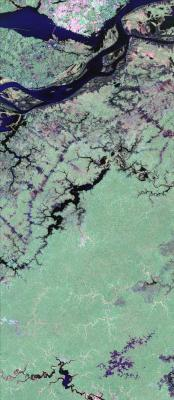

In [1]:
from PIL import Image
img = Image.open("downloads/biomass_scs/quicklook.jpg")
img

In [58]:
import folium
import geopandas as gpd

gdf = gpd.read_file("downloads/biomass_scs/enclosure.kml", driver='KML')
gdf = gdf["geometry"] # elimina coluas desnecessárias, mantendo apenas a geometria

center = gdf.geometry.union_all().centroid
m = folium.Map(location=[center.y, center.x], zoom_start=9, tiles="OpenStreetMap")
folium.GeoJson(gdf).add_to(m)
m

Produto: BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S.ZIP.zip
Raster: 1509 colunas x 20771 linhas; 4 bandas ['HH', 'HV', 'VH', 'VV']; ('float32', 'float32', 'float32', 'float32')
Previa amostrada: 102 x 1400 pixels por banda
CRS do raster: None; GCPs: 60; CRS dos GCPs: EPSG:4979


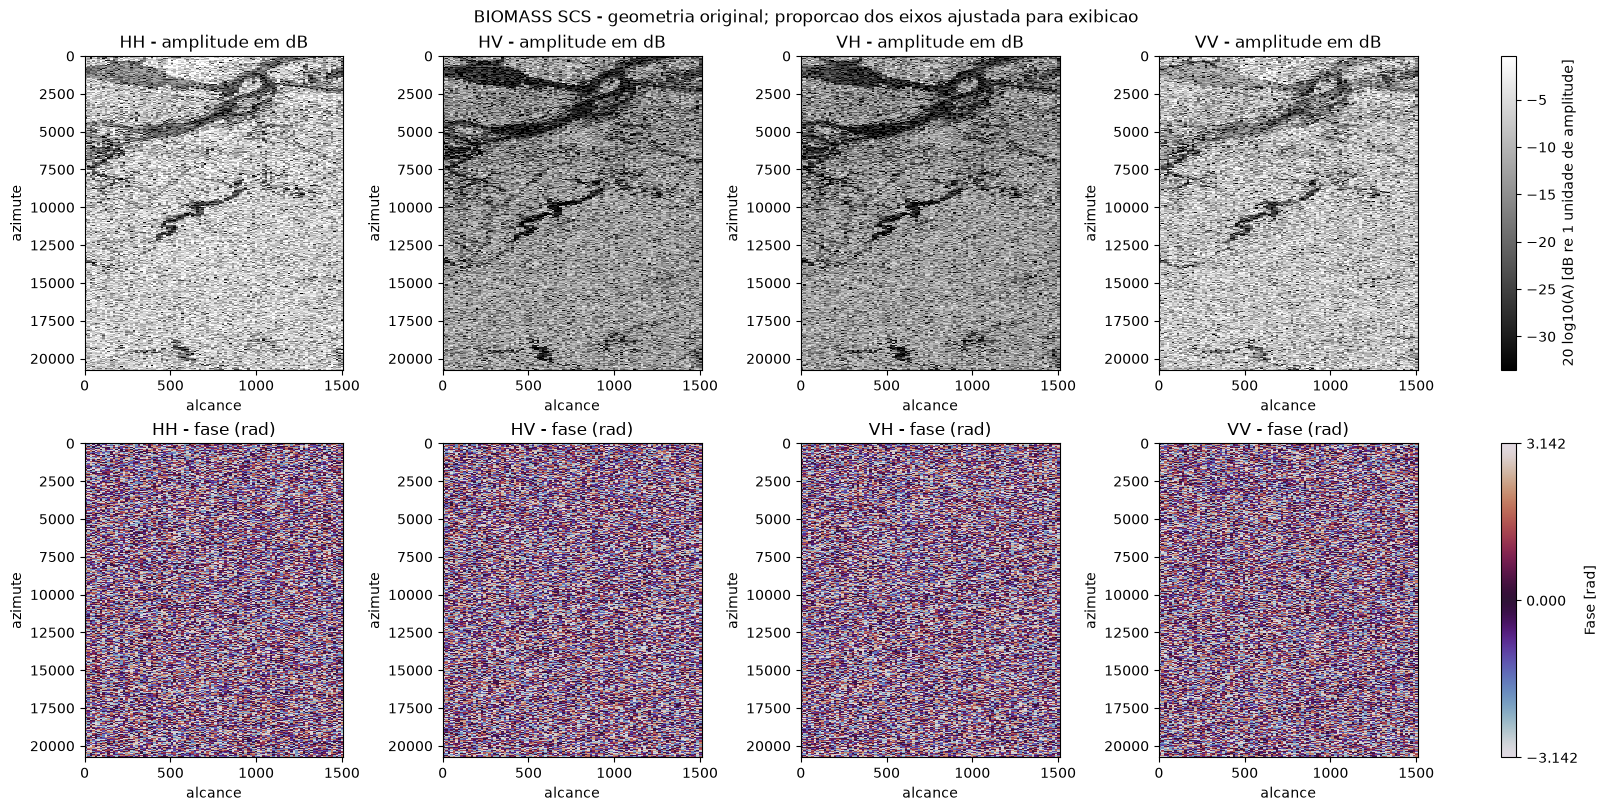

In [57]:
# Visualizacao e analise do SCS diretamente no ZIP, sem extrair os TIFFs.
from pathlib import Path
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling

arquivo_scs = Path(
    'downloads/biomass_scs/'
    'BIO_S3_SCS__1S_20260129T221214_20260129T221234_T_G01_M01_C10_T014_F158_02_DY8X9S.ZIP.zip'
).resolve()
if not arquivo_scs.is_file():
    raise FileNotFoundError(f'Produto SCS nao encontrado: {arquivo_scs}')

with zipfile.ZipFile(arquivo_scs) as zip_scs:
    membros = zip_scs.namelist()
    def membro_scs(sufixo):
        encontrados = [n for n in membros
                       if '/measurement/' in n and n.lower().endswith(sufixo)]
        if len(encontrados) != 1:
            raise ValueError(f'Esperado um arquivo {sufixo}; encontrados: {encontrados}')
        return encontrados[0]
    membro_amp = membro_scs('_abs.tiff')
    membro_fase = membro_scs('_phase.tiff')

def caminho_zip_scs(membro):
    return f'/vsizip/{arquivo_scs.as_posix()}/{membro}'

# Limite para o maior lado da previa. A cena completa nao e carregada em RAM.
# Nearest seleciona amostras originais: nao faz media de amplitude nem de fase.
MAX_LADO_SCS = 1400
with rasterio.open(caminho_zip_scs(membro_amp)) as src_amp, \
     rasterio.open(caminho_zip_scs(membro_fase)) as src_fase:
    if (src_amp.shape, src_amp.count) != (src_fase.shape, src_fase.count):
        raise ValueError('Amplitude e fase possuem dimensoes ou numero de bandas diferentes.')
    altura_scs, largura_scs = src_amp.shape
    fator = min(1.0, MAX_LADO_SCS / max(src_amp.shape))
    forma_previa = (src_amp.count, max(1, round(altura_scs * fator)),
                    max(1, round(largura_scs * fator)))
    polarizacoes_scs = [src_amp.tags(b).get('POLARIMETRIC_INTERP')
                       or src_amp.descriptions[b - 1] or f'Banda {b}'
                       for b in src_amp.indexes]
    polarizacoes_fase = [src_fase.tags(b).get('POLARIMETRIC_INTERP')
                        or src_fase.descriptions[b - 1] or f'Banda {b}'
                        for b in src_fase.indexes]
    if polarizacoes_scs != polarizacoes_fase:
        raise ValueError('A ordem das polarizacoes difere entre amplitude e fase.')
    amplitude_scs = src_amp.read(out_shape=forma_previa, masked=True,
                                resampling=Resampling.nearest).filled(np.nan)
    fase_scs = src_fase.read(out_shape=forma_previa, masked=True,
                            resampling=Resampling.nearest).filled(np.nan)
    print(f'Produto: {arquivo_scs.name}')
    print(f'Raster: {largura_scs} colunas x {altura_scs} linhas; '
          f'{src_amp.count} bandas {polarizacoes_scs}; {src_amp.dtypes}')
    print(f'Previa amostrada: {forma_previa[2]} x {forma_previa[1]} pixels por banda')
    gcps_scs, crs_gcps_scs = src_amp.gcps
    print(f'CRS do raster: {src_amp.crs}; GCPs: {len(gcps_scs)}; CRS dos GCPs: {crs_gcps_scs}')

# Amplitude zero e valida, mas nao admite logaritmo; excluida apenas da escala dB.
validos_scs = (np.isfinite(amplitude_scs) & (amplitude_scs >= 0)
               & np.isfinite(fase_scs))
amplitude_scs = np.where(validos_scs, amplitude_scs, np.nan)
fase_scs = np.where(validos_scs, fase_scs, np.nan)
amplitude_db_scs = np.full(amplitude_scs.shape, np.nan, dtype=np.float32)
positivos = validos_scs & (amplitude_scs > 0)
amplitude_db_scs[positivos] = 20 * np.log10(amplitude_scs[positivos])

# Escala dB comum entre polarizacoes, com corte P2-P98 somente para exibicao.
db_finitos = amplitude_db_scs[np.isfinite(amplitude_db_scs)]
if not db_finitos.size:
    raise ValueError('A previa nao contem amplitudes positivas validas para exibir em dB.')
vmin_scs, vmax_scs = np.percentile(db_finitos, [2, 98])
if vmin_scs == vmax_scs:
    vmax_scs = vmin_scs + 1
fig, eixos = plt.subplots(2, len(polarizacoes_scs),
                         figsize=(4 * len(polarizacoes_scs), 8),
                         squeeze=False, constrained_layout=True)
extensao_scs = (0, largura_scs, altura_scs, 0)
for b, pol in enumerate(polarizacoes_scs):
    im_amp = eixos[0, b].imshow(amplitude_db_scs[b], cmap='gray',
        vmin=vmin_scs, vmax=vmax_scs, extent=extensao_scs, aspect='auto',
        interpolation='nearest')
    im_fase = eixos[1, b].imshow(fase_scs[b], cmap='twilight',
        vmin=-np.pi, vmax=np.pi, extent=extensao_scs, aspect='auto',
        interpolation='nearest')
    eixos[0, b].set_title(f'{pol} - amplitude em dB')
    eixos[1, b].set_title(f'{pol} - fase (rad)')
    for ax in eixos[:, b]:
        ax.set_xlabel('alcance')
        ax.set_ylabel('azimute')
fig.colorbar(im_amp, ax=list(eixos[0]), label='20 log10(A) [dB re 1 unidade de amplitude]')
fig.colorbar(im_fase, ax=list(eixos[1]), label='Fase [rad]', ticks=[-np.pi, 0, np.pi])
fig.suptitle('BIOMASS SCS - geometria original; proporcao dos eixos ajustada para exibicao')
plt.show()


#### 2.1.4. Software SNAP

Os dados do biomass são enviados em dois arquivos  `.tif` do tipo `float32`, um para fase e outro para amlitude. Até podem ser abertos no QGIS mas ainda é recomendado usar o SNAP.

In [54]:
from pathlib import Path
import zipfile

arquivo = sorted(Path("downloads/biomass_scs").glob("*.zip"),
                      key=lambda p: p.stat().st_mtime, reverse=True)[0]
    
with zipfile.ZipFile(arquivo) as zip_slc:
    fase = [m for m in zip_slc.namelist()
            if "/measurement/" in m and m.lower().endswith((".tif", ".tiff")) and "phase" in m.lower()][0]
    amp =   [m for m in zip_slc.namelist()
            if "/measurement/" in m and m.lower().endswith((".tif", ".tiff")) and "abs" in m.lower()][0]
    
qgis_bin_path = 'C:/Program Files/QGIS 3.44.11/bin' # 'ajustar
file = f"/vsizip/{arquivo}/{amp}"

# if in CMD shell, print last 14 lines of gdalinfo output
!"{qgis_bin_path}/gdalinfo.exe" "{file}" | python -c "import sys; [print(l.rstrip()) for l in list(sys.stdin)[-45:]]"

GCP[ 58]: Id=59, Info=
          (1508,20000) -> (-59.9775317503846,-4.29120542040015,14.1370264710858)
GCP[ 59]: Id=60, Info=
          (1508,20770) -> (-59.9867211224719,-4.3372136403319,43.6702316710725)
Metadata:
  TIFFTAG_IMAGEDESCRIPTION=BIOMASS L1
  TIFFTAG_SOFTWARE=BPS-Biomass L1 Processor-4.4.5
  TIFFTAG_DATETIME=2026-09-24T16:44:15.477107
  MATRIX_REPRESENTATION=SCATTERING
  MAX_Z_ERROR=0.0001
  PolarisationsSequence=HH HV VH VV
  Swath=S3
  AREA_OR_POINT=Area
Image Structure Metadata:
  COMPRESSION=LERC_ZSTD
  LERC_VERSION=2.4
  INTERLEAVE=BAND
  MAX_Z_ERROR=0.0001
  LAYOUT=COG
Corner Coordinates:
Upper Left  (    0.0,    0.0)
Lower Left  (    0.0,20771.0)
Upper Right ( 1509.0,    0.0)
Lower Right ( 1509.0,20771.0)
Center      (  754.5,10385.5)
Band 1 Block=512x512 Type=Float32, ColorInterp=Gray
  NoData Value=-9999
  Overviews: 755x10386, 302x4155, 151x2078, 76x1039
  Metadata:
    POLARIMETRIC_INTERP=HH
Band 2 Block=512x512 Type=Float32, ColorInterp=Undefined
  NoData Valu

<img src="media/imgs/img19.png"  alt="snap_for_biomass">


### 2.2. O coeficiente de retroespalhamento (*backscattering*)

Fisicamente, essa medição é descrita pelo termo Seção Reta Radar (Radar Cross Section), ou simplesmente retroespalhamneto, representado por σ, que é definido como a razão entre a intensidade do sinal recebido e a intensidade do sinal incidente:

$$
\sigma = \frac{|S|^2_{\text{received}}}{|S|^2_{\text{incident}}} \,4\pi R^{2} \quad [\mathrm{m}^{2}]
$$

O <b style="color:#2ECC40"> retroespalhamento normalizado por unidade de área do terreno é efetivamente usado na cartografia</b> e definido fisicamente por $\sigma^0 \approx \sigma/A$:

<img src="media/imgs/img16.png"  alt="sigma_0">

Na prática, $\sigma^0$ é obtido a partir de valores dos pixels $(|S|^2)$ e de um fator de calibração radiométrica $(A_{\sigma,i})$ (obtida durante o processamento do produto, utilizando parâmetros previamente determinados em laboratório e atualizados durante a missão RADAR) que passa a representar a área horizontal de referência estimada do terreno e tende a se igualar com a definição física:

$$
\sigma^0 = \frac{|S|^2_{\text{received}}}{A_{\sigma}}
$$

Os três coeficientes de retroespalhamento podem ser usados dependendo das aplicações são gerados a partir da fórmula acima substituindo pelo :

- $\beta^0$: Área na geometria de alcance inclinado (slant range). Usada em processamentos que exijam dados na geometria original do radar.
- $\sigma^0$ (normalized radar cross section): Área de referência no terreno (ground range). Usada para classificação temática, vegetação, água e solos...
- $\gamma^0$: Área de referência projetada no plano perpendicular à direção de visada. Usada em processamento para correção de efeitos do terreno

Esses três coeficientes são adimensionais e podem ser expressos em escala linear ou em decibéis.